# Fixed Income PCA (Veronesi Task 4) — 과제용

이 파일은 수익률곡선(만기별 YTM)의 변화(ΔYTM) 를 대상으로 PCA를 수행하여  
대표 요인 Level / Slope / Curvature 를 확인하는 과제입니다.

- 데이터: `RawData_PCA.csv` (또는 동일 구조의 Excel)
- 만기 예시: (1y, 2y, 3y, 5y, 10y, 20y)
- 핵심: (1) ΔYTM 생성 → (2) 공분산행렬 → (3) 고유값분해 → (4) 로딩/요인시계열 해석

> 제출물 요구사항, 마감 등은 과제 공지와 첨부한 장표를 참고해주세요.


## 0. 라이브러리 로드

In [1]:
import pandas as pd
import numpy as np
# import matplotlib.pyplot as plt
# import statsmodels.api as sm

## 1. 데이터 업로드 & 로딩

- Colab 환경 기준 `files.upload()`를 사용합니다.
- CSV/Excel 모두 동작하도록 파일 확장자에 따라 자동으로 읽도록 구성하세요.


In [2]:
# 파일 경로 설정
file_path = '/content/RawData_PCA.xlsx'

# 파일 확장자에 따라 읽기
if file_path.endswith('.csv'):
    df = pd.read_csv(file_path)
elif file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
else:
    print('지원하지 않는 파일 형식입니다.')

# 데이터프레임의 첫 5행 표시
print('데이터프레임의 첫 5행:')
display(df.head())

# 결측치 확인
print('\n결측치 확인:')
display(df.isnull().sum())

데이터프레임의 첫 5행:


,Date,1Y,2Y,3Y,5Y,10Y,20Y
0,2021-03-10,0.689,1.013,1.182,1.566,2.036,2.119
1,2021-03-11,0.684,0.985,1.179,1.525,2.027,2.108
2,2021-03-12,0.688,0.990,1.223,1.596,2.092,2.164
3,2021-03-15,0.691,0.983,1.238,1.621,2.152,2.190
4,2021-03-16,0.685,0.904,1.177,1.602,2.098,2.158



결측치 확인:


,0
Date,0
1Y,0
2Y,0
3Y,0
5Y,0
10Y,0
20Y,0


## 2. 전처리 (Date 인덱스, 컬럼 정리, 단위 확인)

1) 첫 번째 열이 날짜라면 `datetime`으로 변환 후 인덱스로 설정  
2) 만기(tenor) 컬럼명 공백 제거 등 정리  
3) 단위 확인: 퍼센트(%)라면 bp로 바꾸려면 `*100` (이미 bp라면 생략)


In [3]:
# 날짜 열 처리 (첫 번째 열이 날짜라고 가정)
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')

# 컬럼명 정리 (필요하다면, 현재는 공백이 없어 생략)
# df.columns = df.columns.str.strip()

# 단위 변환(%를 bp로) 예: % -> bp
# 데이터 값들이 소수점으로 되어있어 100을 곱해 bp로 변환합니다.
df.iloc[:, :] = df.iloc[:, :] * 100

print("전처리된 데이터의 첫 5행:")
display(df.head())
print("\n전처리된 데이터의 정보:")
display(df.info())

전처리된 데이터의 첫 5행:


,1Y,2Y,3Y,5Y,10Y,20Y
Date,,,,,,
2021-03-10,68.9,101.3,118.2,156.6,203.6,211.9
2021-03-11,68.4,98.5,117.9,152.5,202.7,210.8
2021-03-12,68.8,99.0,122.3,159.6,209.2,216.4
2021-03-15,69.1,98.3,123.8,162.1,215.2,219.0
2021-03-16,68.5,90.4,117.7,160.2,209.8,215.8



전처리된 데이터의 정보:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1207 entries, 2021-03-10 to 2026-01-30
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   1Y      1207 non-null   float64
 1   2Y      1207 non-null   float64
 2   3Y      1207 non-null   float64
 3   5Y      1207 non-null   float64
 4   10Y     1207 non-null   float64
 5   20Y     1207 non-null   float64
dtypes: float64(6)
memory usage: 66.0 KB


None

## 3. ΔYTM 만들기

- PCA는 보통 **수준 자체(YTM)** 가 아니라 **변화(ΔYTM)** 를 대상으로 수행합니다.
- 차분 후 결측 제거


In [4]:
# 차분하여 ΔYTM 생성
df_diff = df.diff().dropna()

print("ΔYTM 데이터의 첫 5행:")
display(df_diff.head())
print("\nΔYTM 데이터의 정보:")
display(df_diff.info())

ΔYTM 데이터의 첫 5행:


,1Y,2Y,3Y,5Y,10Y,20Y
Date,,,,,,
2021-03-11,-0.5,-2.8,-0.3,-4.1,-0.9,-1.1
2021-03-12,0.4,0.5,4.4,7.1,6.5,5.6
2021-03-15,0.3,-0.7,1.5,2.5,6.0,2.6
2021-03-16,-0.6,-7.9,-6.1,-1.9,-5.4,-3.2
2021-03-17,0.1,-1.8,0.0,3.7,3.6,2.3



ΔYTM 데이터의 정보:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1206 entries, 2021-03-11 to 2026-01-30
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   1Y      1206 non-null   float64
 1   2Y      1206 non-null   float64
 2   3Y      1206 non-null   float64
 3   5Y      1206 non-null   float64
 4   10Y     1206 non-null   float64
 5   20Y     1206 non-null   float64
dtypes: float64(6)
memory usage: 66.0 KB


None

## 4. 공분산 행렬 & 고유값 분해 (eigh 권장)

- 공분산행렬: Σ = Cov(ΔYTM)
- 대칭행렬이므로 `np.linalg.eigh` 사용 권장
- 고유값/고유벡터를 내림차순으로 정렬


In [6]:
# 공분산 행렬 계산 (tenor x tenor)
cov_matrix = df_diff.cov()

# 고유값/고유벡터 계산 (대칭행렬이므로 eigh 사용 권장)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# 내림차순 정렬
# 고유값의 내림차순 정렬을 위한 인덱스
sort_idx = eigenvalues.argsort()[::-1]

# 고유값과 고유벡터를 내림차순으로 정렬
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

print("공분산 행렬:\n", cov_matrix)
print("\n정렬된 고유값:\n", eigenvalues)
print("\n정렬된 고유벡터:\n", eigenvectors)

공분산 행렬:
             1Y         2Y         3Y         5Y        10Y        20Y
1Y    6.620362   9.709220  10.269470  10.267934   8.980325   7.302186
2Y    9.709220  21.688708  22.236207  22.283211  19.284331  15.506446
3Y   10.269470  22.236207  25.171250  24.966747  21.944971  17.444528
5Y   10.267934  22.283211  24.966747  27.033945  24.397585  19.791843
10Y   8.980325  19.284331  21.944971  24.397585  25.083706  20.338084
20Y   7.302186  15.506446  17.444528  19.791843  20.338084  19.065674

정렬된 고유값:
 [111.85714018   7.43602853   2.23232744   1.49257199   0.95703481
   0.6885419 ]

정렬된 고유벡터:
 [[-0.19489345 -0.259119    0.85393536 -0.40118351  0.06295144 -0.02751709]
 [-0.41495854 -0.47728076  0.0527843   0.5466732  -0.53321017 -0.11858174]
 [-0.45887056 -0.36732354 -0.25989154 -0.06251016  0.46065051  0.60898375]
 [-0.48492113 -0.02785992 -0.2846981  -0.25925086  0.27203404 -0.73607662]
 [-0.45232592  0.45483227 -0.11622326 -0.42850734 -0.56547079  0.26766634]
 [-0.37351911  0.60206

## 5. 설명력(Explained Variance Ratio)

- 각 PC가 전체 변동성을 얼마나 설명하는지 확인하세요.
- (선택) 막대그래프/누적그래프를 그려도 좋습니다.


각 주성분의 설명력 비율: [0.89727154 0.05964873 0.0179068  0.01197279 0.00767694 0.0055232 ]
누적 설명력 비율: [0.89727154 0.95692027 0.97482707 0.98679987 0.9944768  1.        ]


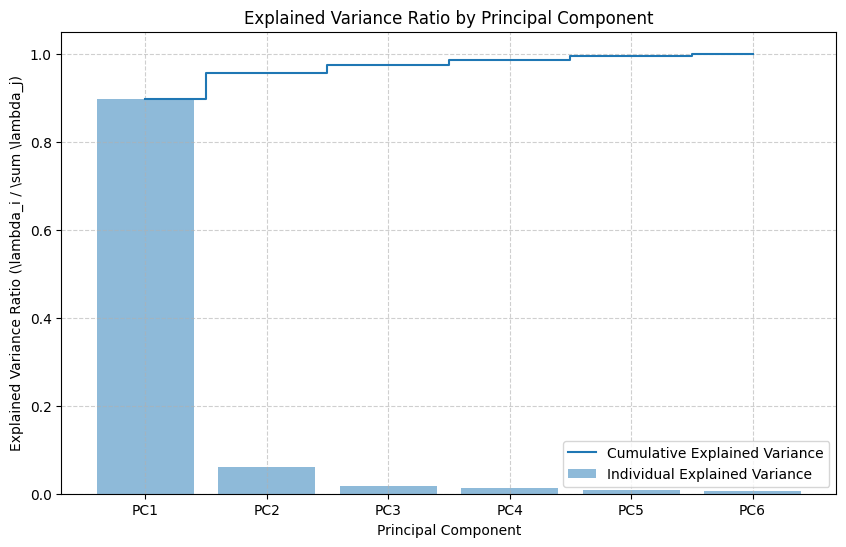

In [10]:
import matplotlib.pyplot as plt

# 설명력 비율 계산
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio)

print("각 주성분의 설명력 비율:", explained_variance_ratio)
print("누적 설명력 비율:", cumulative_explained_variance_ratio)

# 그래프 시각화
plt.figure(figsize=(10, 6))

pc_labels = [f'PC{i+1}' for i in range(len(explained_variance_ratio))]

# 막대 그래프 (개별 설명력)
plt.bar(pc_labels, explained_variance_ratio, alpha=0.5, align='center', label='Individual Explained Variance')

# 누적 막대 그래프 (step plot 사용 시 x축 인덱스 주의)
plt.step(range(len(cumulative_explained_variance_ratio)), cumulative_explained_variance_ratio, where='mid', label='Cumulative Explained Variance')

# Y축 라벨에 수식 추가 (LaTeX 형식)
plt.ylabel('Explained Variance Ratio (\\lambda_i / \\sum \\lambda_j)')
plt.xlabel('Principal Component')
plt.title('Explained Variance Ratio by Principal Component')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 6. PC Scores(요인 시계열) 계산

- 점수(Score): PC_t = ΔYTM_t · loading  
- 행렬 형태: (T x n) @ (n x k) = (T x k)
- 여기서는 PC1~PC3만 사용


In [11]:
import pandas as pd

# PC score 계산
# df_diff (T x n) @ eigenvectors (n x k) = PC_scores (T x k)
# 여기서는 PC1~PC3만 사용하므로 eigenvectors의 첫 3개 열을 사용합니다.
pc_scores = df_diff @ eigenvectors[:, :3]

# PC1~PC3 DataFrame 구성
# pc_scores는 이미 DataFrame이고, index도 df_diff와 동일합니다.
# 따라서, 컬럼 이름만 변경해주면 됩니다.
pc_scores_df = pc_scores.copy() # Make a copy to avoid modifying original pc_scores in place
pc_scores_df.columns = ['PC1_Level', 'PC2_Slope', 'PC3_Curvature']

display(pc_scores_df.head())

,PC1_Level,PC2_Slope,PC3_Curvature
Date,,,
2021-03-11,4.203133,0.618745,0.417095
2021-03-12,-10.779233,4.171671,-1.729964
2021-03-15,-5.353711,3.930095,-0.733576
2021-03-16,10.753390,1.836887,0.783142
2021-03-17,-3.554239,3.752263,-0.732919


## 7. 로딩(Loadings) 플롯: 만기별 민감도 형태 확인

- PC1: 거의 같은 부호/크기 → Level(평행이동)
- PC2: 단기 vs 장기 부호가 반대 → Slope(기울기)
- PC3: 중기 구간이 다르게 움직임 → Curvature(곡률)


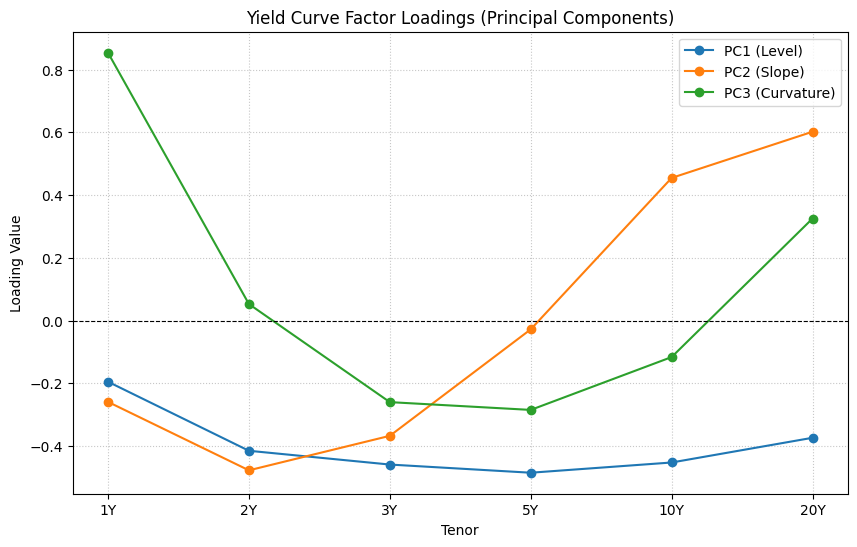

In [13]:
# PC1, PC2, PC3 로딩(Loadings) 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

tenors = df.columns

# 각 PC의 로딩값 플롯
plt.plot(tenors, eigenvectors[:, 0], marker='o', label='PC1 (Level)')
plt.plot(tenors, eigenvectors[:, 1], marker='o', label='PC2 (Slope)')
plt.plot(tenors, eigenvectors[:, 2], marker='o', label='PC3 (Curvature)')

# 0선 추가 (부호 변화 확인용)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)

plt.xlabel('Tenor')
plt.ylabel('Loading Value')
plt.title('Yield Curve Factor Loadings (Principal Components)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

## 8. 요인 시계열 플롯 (PC1~PC3)

- Level/Slope/Curvature 요인이 시간에 따라 어떻게 변했는지 확인하세요.


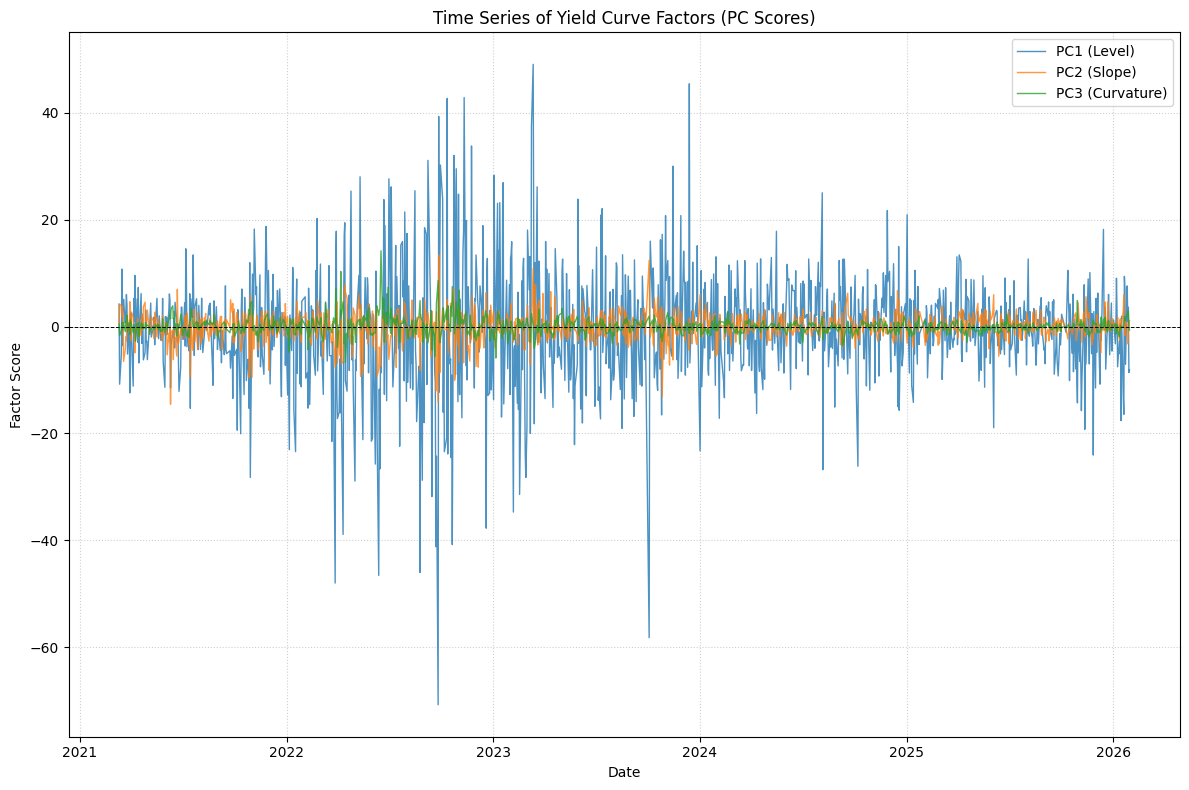

In [14]:
# Level, Slope, Curvature 요인 시계열 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# 각 PC Score 플롯
plt.plot(pc_scores_df.index, pc_scores_df['PC1_Level'], label='PC1 (Level)', alpha=0.8, linewidth=1)
plt.plot(pc_scores_df.index, pc_scores_df['PC2_Slope'], label='PC2 (Slope)', alpha=0.8, linewidth=1)
plt.plot(pc_scores_df.index, pc_scores_df['PC3_Curvature'], label='PC3 (Curvature)', alpha=0.8, linewidth=1)

# 0 가로선
plt.axhline(0, color='black', linestyle='--', linewidth=0.7)

plt.title('Time Series of Yield Curve Factors (PC Scores)')
plt.xlabel('Date')
plt.ylabel('Factor Score')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 9. (선택) R²로 “PC 1~3이 만기별 ΔYTM를 얼마나 설명하는가” 확인

- 각 만기별로 회귀를 돌려 R² 비교
- PC1만 / PC1+PC2 / PC1+PC2+PC3


In [16]:
import statsmodels.api as sm

results = []
tenors = df_diff.columns

for tenor in tenors:
    y = df_diff[tenor]

    # PC1
    X1 = sm.add_constant(pc_scores_df[['PC1_Level']])
    r2_1 = sm.OLS(y, X1).fit().rsquared

    # PC1 + PC2
    X2 = sm.add_constant(pc_scores_df[['PC1_Level', 'PC2_Slope']])
    r2_2 = sm.OLS(y, X2).fit().rsquared

    # PC1 + PC2 + PC3
    X3 = sm.add_constant(pc_scores_df[['PC1_Level', 'PC2_Slope', 'PC3_Curvature']])
    r2_3 = sm.OLS(y, X3).fit().rsquared

    results.append([tenor, r2_1, r2_2, r2_3])

r2_df = pd.DataFrame(results, columns=['Tenor', 'PC1', 'PC1+PC2', 'PC1+PC2+PC3']).set_index('Tenor')

print("R-squared by Tenor and Number of Components:")
display(r2_df.round(4))

R-squared by Tenor and Number of Components:


,PC1,PC1+PC2,PC1+PC2+PC3
Tenor,,,
1Y,0.6418,0.7172,0.9631
2Y,0.8881,0.9662,0.9664
3Y,0.9357,0.9756,0.9816
5Y,0.9730,0.9732,0.9799
10Y,0.9124,0.9737,0.9749
20Y,0.8185,0.9599,0.9723


### 체크리스트 (제출 전)

- [ ] ΔYTM(차분) 사용했는가?  
- [ ] 공분산행렬이 (tenor x tenor) 형태인가?  
- [ ] 고유값 내림차순 정렬했는가?  
- [ ] PC1/PC2/PC3 로딩 형태가 Level/Slope/Curvature로 해석 가능한가?  
- [ ] 그래프 제목/축 라벨/범례가 명확한가?


내가 이해한거 정리

---

1. 일단 공분산 행렬도 정리를 한다는건 각 금리들이 YTM에 따라 어떻게 변동하는지를 보기 위해서임
그래서 전체 변동성을 100이라고 했을때 그 변동성의 70퍼 정도를 설명하는걸 PC1, 20퍼 정도를 설명하는걸 PC2, 10퍼 정도를 설명하는 걸 PC3로 분류

2. 지금 그래서 설명력 그래프를 보면 전체 변동성중에서 해당 주성분이 차지하는 비율을 계산하는 것임. 보면 지금 당연히 PC1 일수록 막대 그래프가 긴 이유가 그만큼 많이 변동성을 설명한다는거고, PC2랑 PC3 이렇게 갈수록 짧아지는건 변동성을 덜 설명해주기 때문. 누적은 쌓이는거니까 처음에 쌓인 것보다 다음 쌓인게 줄어들고 막 그러는거임

3. 파란색: 일단 모양이 flat 하다는건 단기, 중기, 장기가 거의 비슷하게 움직하게 움직인다는것(다 같은 부호영역(음수)쪽에 있음). 그리고 모양이 concanve up인 이유는 중기채가 단기, 장기채에 비해 더 민감한 경향이 있기 때문

주황색: 보면 단기채는 음수영역에 있고, 장기채는 양수영역에 있어서 서로 부호가 반대임(즉, 반대로 움직인다는 뜻). 그래서 모양은 중기채를 중심축으로 시소처럼 휘어져 있는 모양. 보면 단기채일때는 concave up인데 이건 처음에는 민감하다가 나중에는 중기채로 갈수록 상대적으로 덜 민감해지고 때문이고 반대로 장기채 영역(양수)에서는 concave down인데 이것도 마찬가지로 만기가 길어질수록 점점 민감해지다가 어느순간 약간 한계체감의 법칙처럼 더 증가되지 않고 포화되서 벌어지는 현상


초록색: 이건 장기채랑 단기채는 서로 같은 방향으로 움직이는데 중기채만 다른 방향으로 움직인다는 뜻(얘만 음수 영역)


4. 뭐 시계열도 보면 파란색이 젤 지랄난게 그만큼 변동성을 가장 많이 보여준다는 거고, 그 다음 PC2, PC3순서

5.  R^2가 1에 가까울수록 모델이 추출한 주성분이 실제 금리의 변화를 잘 설명한다는 뜻인데 보면 PC1 가 사실상 거의 다 설명하고, R2, R3를 전부 합치면 이제 실제 금리의 변화를 거의 완벽하게 설명할 수 있다는 말.


